# 蛋白质序列长度统计

输入：`output/cdhit/meer1000M_cd90.pep.fa`。使用 conda **gene** 环境运行，长度单位为氨基酸残基（aa）。

## 统计口径

- 每条 FASTA 记录计为一条序列；不再次去重，不过滤短序列。
- 正确拼接多行序列，忽略 FASTA 标题和换行。统计 `len(record.seq)`；检查序列是否仅含标准 20 种氨基酸，避免停止符或缺口造成歧义。
- 分组宽度为 100 aa，区间**左闭右开**：`[0,100)`、`[100,200)`、`[200,300)`……长度恰好为 200 的序列归入 200–300 组。
- 分组从 0 开始，覆盖最长序列，保留计数为 0 的区间。结果仅描述该输入文件。

### 运行方式

在 Jupyter / VS Code 中选择 `gene` 环境的 Python 内核。也可在本目录执行：

```bash
conda run -n gene jupyter nbconvert --execute --to notebook --inplace find.ipynb
```


## 1. 输入与环境

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version
import hashlib
import os
import platform
import sys

from Bio import SeqIO
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

FASTA_PATH = Path('/Users/conwaysu/Documents/psychrophilic/Psychrophilic-protein-discovery/output/cdhit/meer1000M_cd90.pep.fa')
BIN_WIDTH = 100
assert FASTA_PATH.is_file(), f'找不到输入文件：{FASTA_PATH}'
assert Path(sys.prefix).name == 'gene', f'请切换到 gene 环境，当前解释器：{sys.executable}'

input_stat_before = FASTA_PATH.stat()
source_sha256 = hashlib.sha256()
with FASTA_PATH.open('rb') as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b''):
        source_sha256.update(chunk)

provenance = {
    'input_file': str(FASTA_PATH),
    'input_bytes': input_stat_before.st_size,
    'input_sha256': source_sha256.hexdigest(),
    'input_modified_at': datetime.fromtimestamp(input_stat_before.st_mtime, ZoneInfo('Asia/Shanghai')).isoformat(),
    'analysis_time': datetime.now(ZoneInfo('Asia/Shanghai')).isoformat(),
    'conda_environment': os.environ.get('CONDA_DEFAULT_ENV', Path(sys.prefix).name),
    'python_executable': sys.executable,
    'python_version': platform.python_version(),
    'platform': platform.platform(),
    'biopython_version': version('biopython'),
    'pandas_version': pd.__version__,
    'matplotlib_version': version('matplotlib'),
    'bin_width_aa': BIN_WIDTH,
    'bin_definition': '[lower, upper)',
    'randomness': 'Deterministic; no random seed required',
}
display(pd.DataFrame(provenance.items(), columns=['项目', '值']).style.hide(axis='index'))


项目,值
input_file,/Users/conwaysu/Documents/psychrophilic/Psychrophilic-protein-discovery/output/cdhit/meer1000M_cd90.pep.fa
input_bytes,176525141
input_sha256,0858ce53cedeccc9f70a97093ebee6cbf69f93e1ff13d2440e2dd237b564ae90
input_modified_at,2026-11-10T21:22:36.743464+08:00
analysis_time,2026-11-11T22:43:21.632942+08:00
conda_environment,gene
python_executable,/opt/homebrew/Caskroom/miniconda/base/envs/gene/bin/python
python_version,3.11.18
platform,macOS-27.0-arm64-arm-64bit
biopython_version,1.88


## 2. 读取 FASTA 并核验输入

逐条解析，不把完整蛋白质序列长期保留在内存中。`sequence_lengths` 保存每条记录的 ID 和长度，可用于后续筛选。

In [2]:
sequence_ids = []
length_values = []
amino_acid_counts = Counter()

for record in SeqIO.parse(FASTA_PATH, 'fasta'):
    sequence = str(record.seq).upper()
    sequence_ids.append(record.id)
    length_values.append(len(sequence))
    amino_acid_counts.update(sequence)

sequence_lengths = pd.DataFrame({'sequence_id': sequence_ids, 'length_aa': length_values})
assert not sequence_lengths.empty, 'FASTA 中没有序列。'
assert sequence_lengths['length_aa'].gt(0).all(), '检测到空序列，请检查输入。'
unexpected_symbols = {symbol: count for symbol, count in amino_acid_counts.items()
                      if symbol not in set('ACDEFGHIKLMNPQRSTVWY')}
assert not unexpected_symbols, f'检测到非标准氨基酸符号，请明确长度计算规则：{unexpected_symbols}'
input_stat_after = FASTA_PATH.stat()
assert (input_stat_before.st_size, input_stat_before.st_mtime_ns) == (input_stat_after.st_size, input_stat_after.st_mtime_ns), '分析过程中输入文件发生变化，请重新运行。'

print(f'读取完成：{len(sequence_lengths):,} 条序列。')
print('核验通过：无空序列，所有序列仅含标准 20 种氨基酸。')
display(sequence_lengths.head())


读取完成：386,829 条序列。
核验通过：无空序列，所有序列仅含标准 20 种氨基酸。


,sequence_id,length_aa
0,FDZ031YE0-5_0000002,306
1,FDZ031YE0-5_0000003,647
2,FDZ031YE0-5_0000004,433
3,FDZ031YE0-5_0000007,252
4,FDZ031YE0-5_0000012,378


## 3. 总体长度统计

In [3]:
sequence_count = len(sequence_lengths)
min_length = int(sequence_lengths['length_aa'].min())
max_length = int(sequence_lengths['length_aa'].max())
mean_length = float(sequence_lengths['length_aa'].mean())
total_residues = int(sequence_lengths['length_aa'].sum())

summary = pd.DataFrame({
    '指标': ['蛋白质序列总数', '最短长度（aa）', '最长长度（aa）', '平均长度（aa）', '总残基数（aa）'],
    '结果': [f'{sequence_count:,}', f'{min_length:,}', f'{max_length:,}', f'{mean_length:,.2f}', f'{total_residues:,}'],
})
display(summary.style.hide(axis='index'))

shortest_sequences = sequence_lengths.loc[sequence_lengths['length_aa'].eq(min_length)]
longest_sequences = sequence_lengths.loc[sequence_lengths['length_aa'].eq(max_length)]
print(f'最短序列共 {len(shortest_sequences):,} 条，以下最多列出 5 条：')
display(shortest_sequences.head(5))
print(f'最长序列共 {len(longest_sequences):,} 条，以下最多列出 5 条：')
display(longest_sequences.head(5))


指标,结果
蛋白质序列总数,"386,829"
最短长度（aa）,200
最长长度（aa）,"5,205"
平均长度（aa）,359.95
总残基数（aa）,"139,239,447"


最短序列共 1,904 条，以下最多列出 5 条：


,sequence_id,length_aa
49,FDZ031YE0-5_0000106,200
319,FDZ031YE0-5_0000742,200
882,FDZ031YE5-10_0000986,200
1124,FDZ0320-5_0000560,200
1137,FDZ0320-5_0000589,200


最长序列共 1 条，以下最多列出 5 条：


,sequence_id,length_aa
233610,FDZ071-BuBu16-18_0000641,5205


## 4. 每 100 aa 的完整分组计数

`0–100` 表示 `0 ≤ 长度 < 100`；占比的分母为全部序列。

In [4]:
length_frequency = Counter(length_values)
bin_counts = Counter()
for length, count in length_frequency.items():
    bin_counts[(length // BIN_WIDTH) * BIN_WIDTH] += count

length_bins = pd.DataFrame([
    {
        '长度区间（aa，左闭右开）': f'{lower}–{lower + BIN_WIDTH}',
        '下界（含）': lower,
        '上界（不含）': lower + BIN_WIDTH,
        '序列数': bin_counts[lower],
        '占比（%）': bin_counts[lower] / sequence_count * 100,
    }
    for lower in range(0, (max_length // BIN_WIDTH + 1) * BIN_WIDTH, BIN_WIDTH)
])
assert int(length_bins['序列数'].sum()) == sequence_count, '分组总数与序列总数不一致。'
assert sum(length * count for length, count in length_frequency.items()) == total_residues
assert abs(length_bins['占比（%）'].sum() - 100) < 1e-9

with pd.option_context('display.max_rows', None):
    display(length_bins[['长度区间（aa，左闭右开）', '序列数', '占比（%）']].style
            .format({'序列数': '{:,}', '占比（%）': '{:.4f}'})
            .hide(axis='index'))
print(f'核验通过：全部 {len(length_bins)} 个区间合计 {length_bins["序列数"].sum():,} 条，覆盖全部序列。')


长度区间（aa，左闭右开）,序列数,占比（%）
0–100,0,0.0000
100–200,0,0.0000
200–300,"163,683",42.3140
300–400,"117,159",30.2870
400–500,"56,347",14.5664
500–600,"23,377",6.0432
600–700,"11,377",2.9411
700–800,"6,125",1.5834
800–900,"3,562",0.9208
900–1000,"2,027",0.5240


核验通过：全部 53 个区间合计 386,829 条，覆盖全部序列。


## 5. 长度分布

左图覆盖全部长度；右图放大 `[0,1000)` aa 区间。两图均使用 100 aa 分组和线性计数轴，纵轴从 0 开始。完整精确计数见上表。

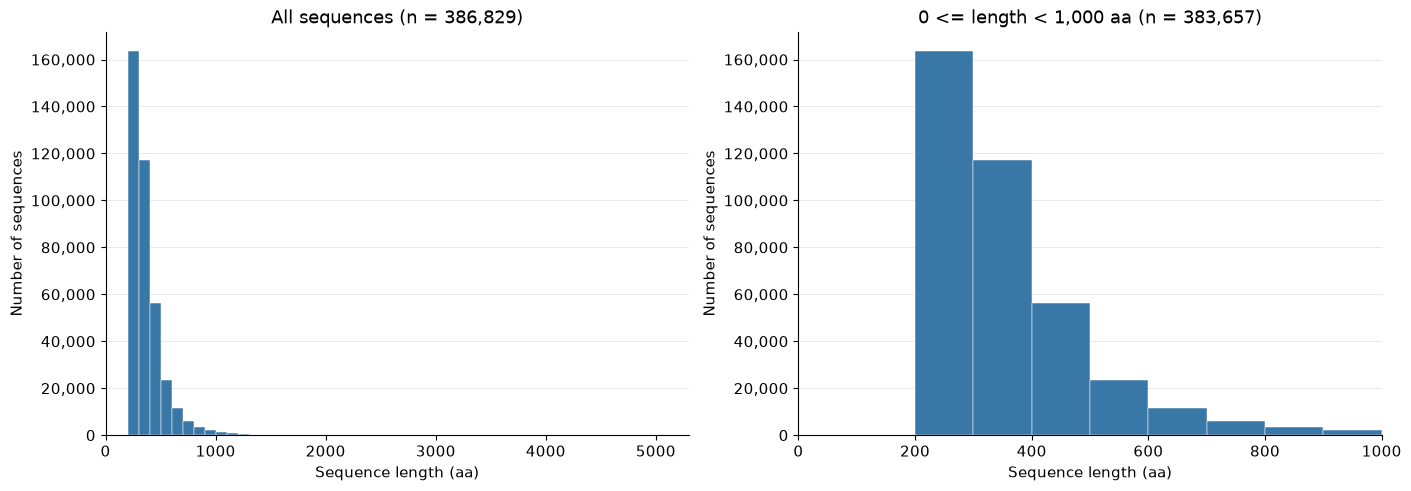

In [5]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)

for ax in axes:
    ax.bar(length_bins['下界（含）'], length_bins['序列数'],
           width=BIN_WIDTH, align='edge', color='#3977A7',
           edgecolor='white', linewidth=0.35, zorder=2)
    ax.set_xlabel('Sequence length (aa)')
    ax.set_ylabel('Number of sequences')
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.grid(axis='y', color='#E2E5E9', linewidth=0.6, zorder=0)
    ax.set_ylim(bottom=0)

axes[0].set_xlim(0, int(length_bins['上界（不含）'].max()))
axes[0].set_title(f'All sequences (n = {sequence_count:,})')
axes[1].set_xlim(0, 1000)
axes[1].set_xticks(range(0, 1001, 200))
focus_count = int(sequence_lengths['length_aa'].lt(1000).sum())
axes[1].set_title(f'0 <= length < 1,000 aa (n = {focus_count:,})')
plt.show()


## 6. 结果摘要（VERIFIED）

以下文字由实际执行结果生成；重新运行时随输入数据更新。

In [6]:
dominant_bin = length_bins.loc[length_bins['序列数'].idxmax()]
below_200 = int(sequence_lengths['length_aa'].lt(200).sum())
display(Markdown(
    f'- **序列总数：{sequence_count:,} 条。**\n'
    f'- 最短 **{min_length:,} aa**，最长 **{max_length:,} aa**，平均 **{mean_length:,.2f} aa**。\n'
    f'- 最多的区间为 **{dominant_bin["长度区间（aa，左闭右开）"]} aa**，'
    f'共 **{int(dominant_bin["序列数"]):,} 条（{dominant_bin["占比（%）"]:.2f}%）**。\n'
    f'- 小于 200 aa 的序列为 **{below_200:,} 条**。\n'
    '- 各区间计数之和已与 FASTA 记录总数核对一致。'
))


- **序列总数：386,829 条。**
- 最短 **200 aa**，最长 **5,205 aa**，平均 **359.95 aa**。
- 最多的区间为 **200–300 aa**，共 **163,683 条（42.31%）**。
- 小于 200 aa 的序列为 **0 条**。
- 各区间计数之和已与 FASTA 记录总数核对一致。